In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset
df = pd.read_json('rossmann_store_sales.json')
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [3]:
# Check the structure of the dataset
df.info()
df.shape

<class 'pandas.DataFrame'>
Index: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   Store                      1017209 non-null  int64         
 1   DayOfWeek                  1017209 non-null  int64         
 2   Date                       1017209 non-null  datetime64[us]
 3   Sales                      1017209 non-null  int64         
 4   Customers                  1017209 non-null  int64         
 5   Open                       1017209 non-null  int64         
 6   Promo                      1017209 non-null  int64         
 7   StateHoliday               1017209 non-null  object        
 8   SchoolHoliday              1017209 non-null  int64         
 9   StoreType                  1017209 non-null  str           
 10  Assortment                 1017209 non-null  str           
 11  CompetitionDistance        1014567 non-null  float64 

(1017209, 18)

In [4]:
# Check for missing values
print(df.isnull().sum())

Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64


In [5]:
# Remove closed stores because they do not contribute to sales prediction
df = df[df['Open'] == 1]

In [6]:
# Handle missing values

# Competition distance - fill with median
df['CompetitionDistance'] = df['CompetitionDistance'].fillna(
    df['CompetitionDistance'].median()
)

# Competition open date - fill with 0 (indicating no competition)
df['CompetitionOpenSinceMonth'] = df['CompetitionOpenSinceMonth'].fillna(0)
df['CompetitionOpenSinceYear'] = df['CompetitionOpenSinceYear'].fillna(0)

# Promo2 information - fill with 0 (indicating no promotion)
df['Promo2SinceWeek'] = df['Promo2SinceWeek'].fillna(0)
df['Promo2SinceYear'] = df['Promo2SinceYear'].fillna(0)

# Promo interval - fill with 'None' (indicating no promotion)
df['PromoInterval'] = df['PromoInterval'].fillna('None')

In [7]:
# Check for missing values again after handling
print(df.isnull().sum())

Store                        0
DayOfWeek                    0
Date                         0
Sales                        0
Customers                    0
Open                         0
Promo                        0
StateHoliday                 0
SchoolHoliday                0
StoreType                    0
Assortment                   0
CompetitionDistance          0
CompetitionOpenSinceMonth    0
CompetitionOpenSinceYear     0
Promo2                       0
Promo2SinceWeek              0
Promo2SinceYear              0
PromoInterval                0
dtype: int64


In [8]:
# Convert data types
df['CompetitionOpenSinceMonth'] = df['CompetitionOpenSinceMonth'].astype(int)
df['CompetitionOpenSinceYear'] = df['CompetitionOpenSinceYear'].astype(int)

df['Promo2SinceWeek'] = df['Promo2SinceWeek'].astype(int)
df['Promo2SinceYear'] = df['Promo2SinceYear'].astype(int)

df['Date'] = pd.to_datetime(df['Date'])

In [9]:
# Check for duplicated rows
print(df.duplicated().sum())

0


In [10]:
# Check for data types
print(df.dtypes)

Store                                 int64
DayOfWeek                             int64
Date                         datetime64[us]
Sales                                 int64
Customers                             int64
Open                                  int64
Promo                                 int64
StateHoliday                         object
SchoolHoliday                         int64
StoreType                               str
Assortment                              str
CompetitionDistance                 float64
CompetitionOpenSinceMonth             int64
CompetitionOpenSinceYear              int64
Promo2                                int64
Promo2SinceWeek                       int64
Promo2SinceYear                       int64
PromoInterval                           str
dtype: object


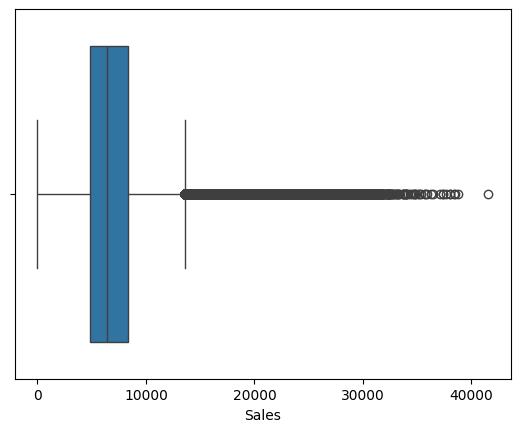

In [11]:
# Visualize the distribution of sales to identify outliers
sns.boxplot(x=df['Sales'])
plt.show()

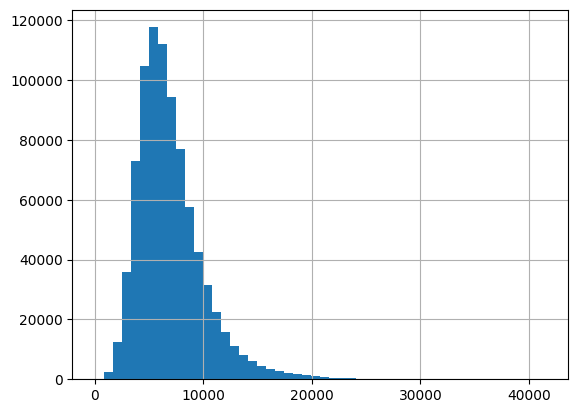

In [12]:
df['Sales'].hist(bins=50)
plt.show()

In [13]:
Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['Sales'] < lower) | (df['Sales'] > upper)]

print(outliers.shape)

(30769, 18)


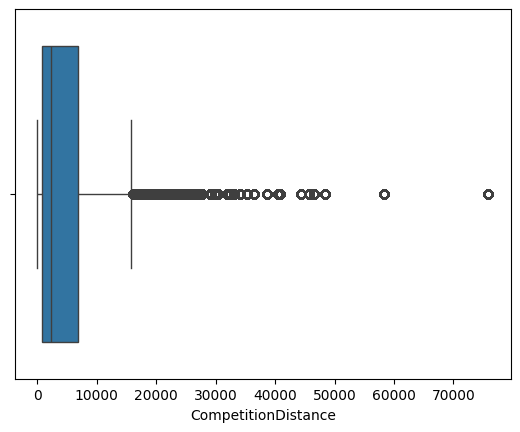

In [14]:
# Visualize the distribution of competition distance to identify outliers
sns.boxplot(x=df['CompetitionDistance'])
plt.show()

In [15]:
# Encode categorical variables using LabelEncoder because they are ordinal in nature   
from sklearn.preprocessing import LabelEncoder

categorical_cols = [
    'StateHoliday',
    'StoreType',
    'Assortment',
    'PromoInterval'
]

# Save each encoder in a dictionary so they can be reused in the dashboard
# The original code reused the same 'le' variable, losing previous encoder mappings
encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    encoders[col] = le

# Remove rows with zero sales as they do not contribute to the prediction
df = df[df['Sales'] > 0]

df = df.dropna()

### Export Encoder Mappings

The `encoders` dictionary above holds the fitted `LabelEncoder` objects, but these live only in this notebook's memory — they are not saved when `cleaned_rossmann.json` is written out later. If `predict.py` (the standalone deployment module) needs to convert a dashboard input like `"Public Holiday"` into the correct encoded integer, it needs to know this exact mapping without re-running this notebook or refitting its own encoders (which would defeat the purpose of separating experimentation from deployment).

This cell exports the mapping as a small, human-readable JSON file (`encoder_mappings.json`) saved alongside `cleaned_rossmann.json`. `predict.py` will read this file directly, so encoding stays consistent between what this notebook produced and what the dashboard sends to the model at prediction time.

In [16]:
import json

# Build a plain dict version of the encoder mappings: {column: {original_value: encoded_int}}
# This is derived directly from the fitted encoders above, so it is guaranteed to match
# exactly what was used to encode df (no separate assumptions about alphabetical order).
encoder_mappings = {
    col: {str(cls): int(le.transform([cls])[0]) for cls in le.classes_}
    for col, le in encoders.items()
}

with open('encoder_mappings.json', 'w') as f:
    json.dump(encoder_mappings, f, indent=4)

print('Saved encoder_mappings.json')
for col, mapping in encoder_mappings.items():
    print(f'{col}: {mapping}')

Saved encoder_mappings.json
StateHoliday: {'0': 0, 'a': 1, 'b': 2, 'c': 3}
StoreType: {'a': 0, 'b': 1, 'c': 2, 'd': 3}
Assortment: {'a': 0, 'b': 1, 'c': 2}
PromoInterval: {'Feb,May,Aug,Nov': 0, 'Jan,Apr,Jul,Oct': 1, 'Mar,Jun,Sept,Dec': 2, 'None': 3}


# Feature Engineering

In [17]:
# Extract date features
df = df.sort_values(['Store', 'Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)

In [18]:
# Lag features grouped by Store to prevent cross-store data leakage
# Without groupby, shift() bleeds the last rows of Store N into the first rows of Store N+1
df['Sales_Lag_7'] = df.groupby('Store')['Sales'].shift(7)
df['Sales_Lag_14'] = df.groupby('Store')['Sales'].shift(14)
df['Sales_Lag_30'] = df.groupby('Store')['Sales'].shift(30)

In [19]:
# Rolling averages grouped by Store
# shift(1) before rolling prevents using same-day sales (leakage)
df['RollingMean_7'] = (
    df.groupby('Store')['Sales']
    .shift(1)
    .groupby(df['Store'])
    .transform(lambda x: x.rolling(7).mean())
)

df['RollingMean_30'] = (
    df.groupby('Store')['Sales']
    .shift(1)
    .groupby(df['Store'])
    .transform(lambda x: x.rolling(30).mean())
)

In [20]:
# Competition duration - guard against rows where CompetitionOpenSinceYear == 0
# Without this, rows with no competition get a massive inflated duration value
df['CompetitionOpenDuration'] = np.where(
    df['CompetitionOpenSinceYear'] == 0,
    0,
    (df['Year'] - df['CompetitionOpenSinceYear']) * 12
    + (df['Month'] - df['CompetitionOpenSinceMonth'])
)

# Clip any remaining negatives (competition opened after current date)
df['CompetitionOpenDuration'] = df['CompetitionOpenDuration'].clip(lower=0)

In [21]:
# Promo duration to guard against rows where Promo2SinceYear == 0
# Without this, rows with no Promo2 get a massive inflated duration value
df['PromoDuration'] = np.where(
    df['Promo2SinceYear'] == 0,
    0,
    (df['Year'] - df['Promo2SinceYear']) * 52
    + (df['WeekOfYear'] - df['Promo2SinceWeek'])
)

# Clip any remaining negatives
df['PromoDuration'] = df['PromoDuration'].clip(lower=0)

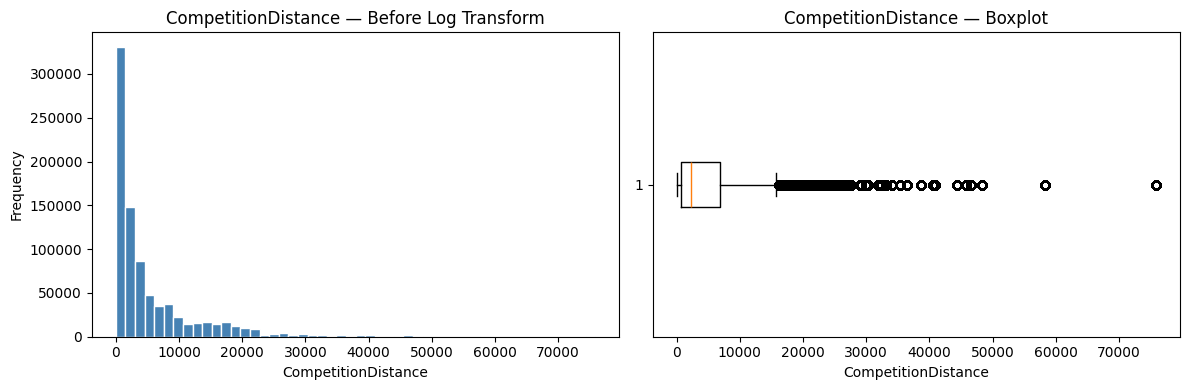

In [22]:
# Before log for CompetitionDistance transform, check original distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
axes[0].hist(df['CompetitionDistance'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('CompetitionDistance — Before Log Transform')
axes[0].set_xlabel('CompetitionDistance')
axes[0].set_ylabel('Frequency')

# Boxplot
axes[1].boxplot(df['CompetitionDistance'], vert=False)
axes[1].set_title('CompetitionDistance — Boxplot')
axes[1].set_xlabel('CompetitionDistance')

plt.tight_layout()
plt.show()

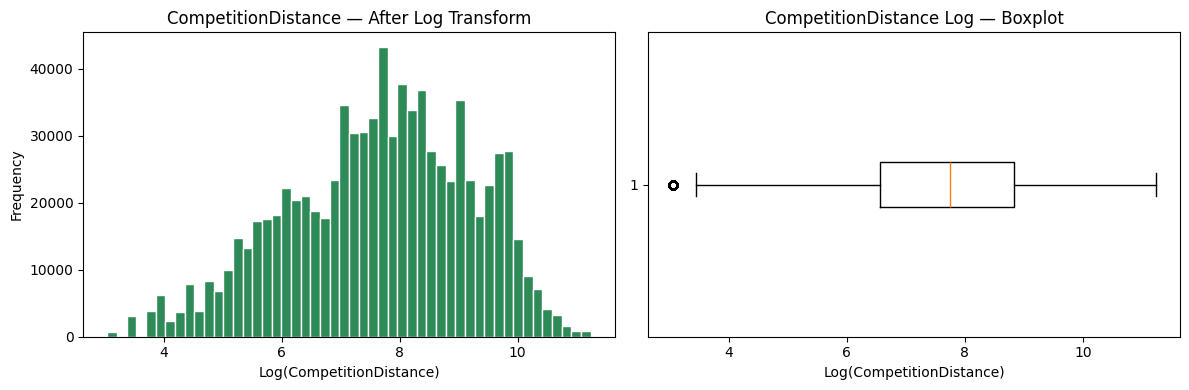

In [23]:
# Log transform the competition distance to reduce skewness and handle outliers
df['CompetitionDistance_Log'] = np.log1p(df['CompetitionDistance'])

# After log transform — confirm distribution is more normal
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['CompetitionDistance_Log'], bins=50, color='seagreen', edgecolor='white')
axes[0].set_title('CompetitionDistance — After Log Transform')
axes[0].set_xlabel('Log(CompetitionDistance)')
axes[0].set_ylabel('Frequency')

axes[1].boxplot(df['CompetitionDistance_Log'], vert=False)
axes[1].set_title('CompetitionDistance Log — Boxplot')
axes[1].set_xlabel('Log(CompetitionDistance)')

plt.tight_layout()
plt.show()

# Find What StoreType is for.

In [25]:
open_days = df[(df["Open"] == 1) & (df["Sales"] > 0)]

profile = open_days.groupby("StoreType").agg(
    stores=("Store", "nunique"),
    avg_sales=("Sales", "mean"),
    median_sales=("Sales", "median"),
    avg_customers=("Customers", "mean"),
    promo_share=("Promo", "mean"),
    promo2_share=("Promo2", "mean"),
    avg_comp_distance=("CompetitionDistance", "mean"),
)
profile["sales_per_customer"] = profile["avg_sales"] / profile["avg_customers"]
profile.round(1)

,stores,avg_sales,median_sales,avg_customers,promo_share,promo2_share,avg_comp_distance,sales_per_customer
StoreType,,,,,,,,
0,602,6925.7,6285.0,795.4,0.4,0.5,5222.9,8.7
1,17,10233.4,9130.0,2022.2,0.4,0.3,1072.6,5.1
2,148,6933.1,6408.0,815.5,0.4,0.5,3514.1,8.5
3,348,6822.3,6395.0,606.4,0.4,0.6,6959.6,11.3


In [26]:
# Assortment mix per type (% of stores)
stores = df.drop_duplicates("Store")
print(pd.crosstab(stores["StoreType"], stores["Assortment"], normalize="index").round(2))

# Share of days open, by day of week
print(df.groupby(["StoreType", "DayOfWeek"])["Open"].mean().unstack().round(2))

# Share of state-holiday days open
holiday = df[df["StateHoliday"].astype(str) != "0"]
print(holiday.groupby("StoreType")["Open"].mean().round(2))

Assortment     0     1     2
StoreType                   
0           0.63  0.00  0.37
1           0.41  0.53  0.06
2           0.52  0.00  0.48
3           0.37  0.00  0.63
DayOfWeek    1    2    3    4    5    6    7
StoreType                                   
0          1.0  1.0  1.0  1.0  1.0  1.0  1.0
1          1.0  1.0  1.0  1.0  1.0  1.0  1.0
2          1.0  1.0  1.0  1.0  1.0  1.0  NaN
3          1.0  1.0  1.0  1.0  1.0  1.0  1.0
StoreType
0    1.0
1    1.0
2    1.0
3    1.0
Name: Open, dtype: float64


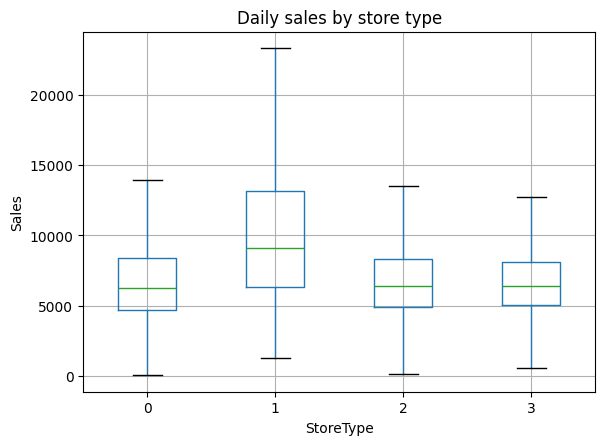

In [28]:
open_days.boxplot(column="Sales", by="StoreType", showfliers=False)
plt.title("Daily sales by store type"); plt.suptitle("")
plt.ylabel("Sales"); plt.show()

## Store Type Analysis

The dataset describes `StoreType` only as "4 different store models" (a, b, c, d) and gives no official definitions. To understand what each type represents, the types were profiled using the open-day records (`Open == 1` and `Sales > 0`). After label encoding, the values map as 0 = a, 1 = b, 2 = c, 3 = d.

### Findings

- **Type a** is the most common type (602 stores) and sits near the average on all measures.
- **Type b** has only 17 stores but the highest sales and customer counts, more than double the other types. Its sales per customer are the lowest (5.1), which suggests high traffic with smaller baskets. Its competitors are the closest (about 1 km), and it is the only type with a large share of the "extra" assortment (53%).
- **Type c** has sales and customers similar to type a. It is the only type with no Sunday records, so it appears to be closed on Sundays.
- **Type d** has the fewest customers (606) but the highest spend per customer (11.3). Its competitors are the farthest away (about 7 km), and most stores carry the extended assortment (63%).
- Sales are visibly higher and more spread out for type b in the box plot, while types a, c and d overlap closely.

### Notes and limitations

- The types are anonymised, so these descriptions are patterns found in the data, not official definitions.
- Type b is based on only 17 stores, so its forecasts are less reliable than the other types.
- Closed days were already removed from the data, so the "share of days open" and holiday-opening checks are not informative. Only the missing Sunday records for type c can be read from them.
- In the dashboard, `StoreType` is a user input, with type a (the most common) as the default.

In [24]:
df = df.drop(columns=[
    'Store',                          # Store ID dropped — model trained on aggregated data
    'Customers',                      # Not known at prediction time
    'Date',                           # Replaced by extracted date features
    'CompetitionDistance',            # Replaced by log-transformed version
    'CompetitionOpenSinceMonth',      # Replaced by CompetitionOpenDuration
    'CompetitionOpenSinceYear',
    'Promo2SinceWeek',                # Replaced by PromoDuration
    'Promo2SinceYear'
])

In [25]:
# Save the cleaned dataset
df.to_json(
    'cleaned_rossmann.json',
    orient='records',
    indent=4
)

# Model Selection

## 1. LightGBM

In [26]:
# Define features and target variable
X = df.drop('Sales', axis=1)
y = df['Sales']

In [27]:
# Time-series split — no random shuffle to prevent data leakage
split_index = int(len(df) * 0.8)

train = df.iloc[:split_index]
test = df.iloc[split_index:]

X_train = train.drop(['Sales'], axis=1)
y_train = train['Sales']

X_test = test.drop(['Sales'], axis=1)
y_test = test['Sales']

In [28]:
# Train a LightGBM model
from lightgbm import LGBMRegressor

lgbm_model = LGBMRegressor(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=10,
    random_state=42
)

lgbm_model.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.013361 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2170
[LightGBM] [Info] Number of data points in the train set: 675470, number of used features: 20
[LightGBM] [Info] Start training from score 6969.480646


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,10
,learning_rate,0.05
,n_estimators,2000
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [29]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

In [30]:
y_pred_lgbm = lgbm_model.predict(X_test)

In [31]:
print(X_train.columns)

Index(['DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday',
       'StoreType', 'Assortment', 'Promo2', 'PromoInterval', 'Year', 'Month',
       'Day', 'WeekOfYear', 'Sales_Lag_7', 'Sales_Lag_14', 'Sales_Lag_30',
       'RollingMean_7', 'RollingMean_30', 'CompetitionOpenDuration',
       'PromoDuration', 'CompetitionDistance_Log'],
      dtype='str')


In [32]:
# Evaluate the model MAE, RMSE, MAPE, and RMSE as a percentage of mean sales for context on error magnitude
mae  = mean_absolute_error(y_test, y_pred_lgbm)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lgbm))
mape = mean_absolute_percentage_error(y_test, y_pred_lgbm) * 100
mean_sales = y_test.mean()
rmse_pct = (rmse / mean_sales) * 100

print('===== LightGBM Evaluation =====')
print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'MAPE : {mape:.2f}%')
print(f'Mean Sales        : {mean_sales:.2f}')
print(f'RMSE % of Mean    : {rmse_pct:.2f}%')

===== LightGBM Evaluation =====
MAE  : 645.56
RMSE : 955.92
MAPE : 10.31%
Mean Sales        : 6901.87
RMSE % of Mean    : 13.85%


## 2. XGBoost

In [33]:
from xgboost import XGBRegressor

In [34]:
xgb_model = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=10,
    random_state=42
)

In [35]:
xgb_model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

In [36]:
y_pred_xgb = xgb_model.predict(X_test)

In [37]:
# Evaluate the model MAE, RMSE, MAPE, and RMSE as a percentage of mean sales for context on error magnitude
mae  = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
mape = mean_absolute_percentage_error(y_test, y_pred_xgb) * 100
mean_sales = y_test.mean()
rmse_pct = (rmse / mean_sales) * 100

print('===== XGBoost Evaluation =====')
print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'MAPE : {mape:.2f}%')
print(f'Mean Sales        : {mean_sales:.2f}')
print(f'RMSE % of Mean    : {rmse_pct:.2f}%')

===== XGBoost Evaluation =====
MAE  : 637.16
RMSE : 954.37
MAPE : 10.24%
Mean Sales        : 6901.87
RMSE % of Mean    : 13.83%


## 3. Random Forest

In [38]:
from sklearn.ensemble import RandomForestRegressor

In [39]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

In [40]:
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [41]:
y_pred_rf = rf_model.predict(X_test)

In [42]:
# Evaluate the model MAE, RMSE, MAPE, and RMSE as a percentage of mean sales for context on error magnitude
mae  = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mape = mean_absolute_percentage_error(y_test, y_pred_rf) * 100
mean_sales = y_test.mean()
rmse_pct = (rmse / mean_sales) * 100

print('===== Random Forest Evaluation =====')
print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'MAPE : {mape:.2f}%')
print(f'Mean Sales        : {mean_sales:.2f}')
print(f'RMSE % of Mean    : {rmse_pct:.2f}%')

===== Random Forest Evaluation =====
MAE  : 727.42
RMSE : 1054.31
MAPE : 11.77%
Mean Sales        : 6901.87
RMSE % of Mean    : 15.28%


## 4. LSTM 

In [43]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

In [44]:
# Scale features and target variable for LSTM
feature_scaler = MinMaxScaler()
target_scaler  = MinMaxScaler()

X_train_scaled = feature_scaler.fit_transform(X_train)
X_test_scaled  = feature_scaler.transform(X_test)

y_train_scaled = target_scaler.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled  = target_scaler.transform(y_test.values.reshape(-1, 1))

In [45]:
# Reshape to (samples, timesteps=1, features) for LSTM input
# Note: using timesteps=1 means LSTM is not learning multi-step sequences.
# This is acceptable for baseline comparison purposes.
X_train_lstm = X_train_scaled.reshape((X_train_scaled.shape[0], 1, X_train_scaled.shape[1]))
X_test_lstm  = X_test_scaled.reshape((X_test_scaled.shape[0], 1, X_test_scaled.shape[1]))

In [46]:
# Build and train the LSTM model
lstm_model = Sequential()
lstm_model.add(LSTM(64, activation='relu', input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])))
lstm_model.add(Dropout(0.2))
lstm_model.add(Dense(32, activation='relu'))
lstm_model.add(Dense(1))
lstm_model.compile(optimizer='adam', loss='mse')

c:\Users\zakwa\OneDrive\Documents\DEG\DEG SEM2 3RD YEAR\fyp\FYP - CODE\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [47]:
# Train the model with validation split to monitor for overfitting
history = lstm_model.fit(
    X_train_lstm,
    y_train_scaled,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 31s 2ms/step - loss: 0.0065 - val_loss: 0.0075
Epoch 2/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - loss: 0.0064 - val_loss: 0.0075
Epoch 3/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - loss: 0.0064 - val_loss: 0.0075
Epoch 4/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 33s 2ms/step - loss: 0.0064 - val_loss: 0.0075
Epoch 5/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 32s 2ms/step - loss: 0.0064 - val_loss: 0.0075
Epoch 6/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 25s 1ms/step - loss: 0.0064 - val_loss: 0.0075
Epoch 7/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 22s 1ms/step - loss: 0.0064 - val_loss: 0.0075
Epoch 8/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 26s 2ms/step - loss: 0.0064 - val_loss: 0.0075
Epoch 9/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 25s 2ms/step - loss: 0.0064 - val_loss: 0.0075
Epoch 10/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 28s 2ms/step - loss: 0.0064 - val_loss: 0.0075
Epoch 11/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 27s 2ms/step - loss: 0.0064 - val_loss: 0.00

In [48]:
# Predict and inverse transform the predictions to original scale
y_pred_lstm_scaled = lstm_model.predict(X_test_lstm)
y_pred_lstm = target_scaler.inverse_transform(y_pred_lstm_scaled).flatten()

5278/5278 ━━━━━━━━━━━━━━━━━━━━ 5s 914us/step


In [49]:
# Evaluate the model MAE, RMSE, MAPE, and RMSE as a percentage of mean sales for context on error magnitude
mae  = mean_absolute_error(y_test, y_pred_lstm)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lstm))
mape = mean_absolute_percentage_error(y_test, y_pred_lstm) * 100
mean_sales = y_test.mean()
rmse_pct = (rmse / mean_sales) * 100

print('===== LSTM Evaluation =====')
print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'MAPE : {mape:.2f}%')
print(f'Mean Sales        : {mean_sales:.2f}')
print(f'RMSE % of Mean    : {rmse_pct:.2f}%')

===== LSTM Evaluation =====
MAE  : 2209.86
RMSE : 2925.80
MAPE : 39.33%
Mean Sales        : 6901.87
RMSE % of Mean    : 42.39%


## Model Comparison Summary

In [50]:
# Print a comparison table of all 4 models
results = {
    'Model': ['LightGBM', 'XGBoost', 'Random Forest', 'LSTM'],
    'MAE':  [
        mean_absolute_error(y_test, y_pred_lgbm),
        mean_absolute_error(y_test, y_pred_xgb),
        mean_absolute_error(y_test, y_pred_rf),
        mean_absolute_error(y_test, y_pred_lstm),
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_lgbm)),
        np.sqrt(mean_squared_error(y_test, y_pred_xgb)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf)),
        np.sqrt(mean_squared_error(y_test, y_pred_lstm)),
    ],
    'MAPE (%)': [
        mean_absolute_percentage_error(y_test, y_pred_lgbm) * 100,
        mean_absolute_percentage_error(y_test, y_pred_xgb) * 100,
        mean_absolute_percentage_error(y_test, y_pred_rf) * 100,
        mean_absolute_percentage_error(y_test, y_pred_lstm) * 100,
    ]
}

results_df = pd.DataFrame(results).set_index('Model')
results_df = results_df.round(2)
print(results_df)

                   MAE     RMSE  MAPE (%)
Model                                    
LightGBM        645.56   955.92     10.31
XGBoost         637.16   954.37     10.24
Random Forest   727.42  1054.31     11.77
LSTM           2209.86  2925.80     39.33
